In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from datetime import datetime, timedelta
from helper import fn_plot_tf_hist

In [105]:
RANDOM_STATE=24 # in production we set rs=None it is hard to change everyware
tf.random.set_seed(seed=RANDOM_STATE)
rng=np.random.default_rng(seed=RANDOM_STATE)

EPOCHS=100
ALPHA=0.001 #LEARNING RATE
TEST_SIZE=0.2
N_SAMPLES=1000
BATCH_SIZE=32
params={
    'legend.fontsize':'medium',
    'figure.figsize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',  
    'ytick.labelsize':'medium',  
    
}
plt.rcParams.update(params)
CMAP=plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [106]:
df= pd.read_csv(r"C:\Users\PGCP-AI\Downloads\weatherHistory.csv")
df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


In [107]:
df.shape

(96453, 12)

In [108]:
df.isna().sum().sum()

np.int64(517)

In [109]:
df['datetime']= pd.to_datetime(df['Formatted Date'],utc=True)

In [110]:
df.columns

Index(['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)',
       'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)',
       'Wind Bearing (degrees)', 'Visibility (km)', 'Loud Cover',
       'Pressure (millibars)', 'Daily Summary', 'datetime'],
      dtype='object')

In [111]:
num_cols_df = df.select_dtypes(include='number')
num_cols_df.drop(['Apparent Temperature (C)','Loud Cover'],axis=1,inplace=True)

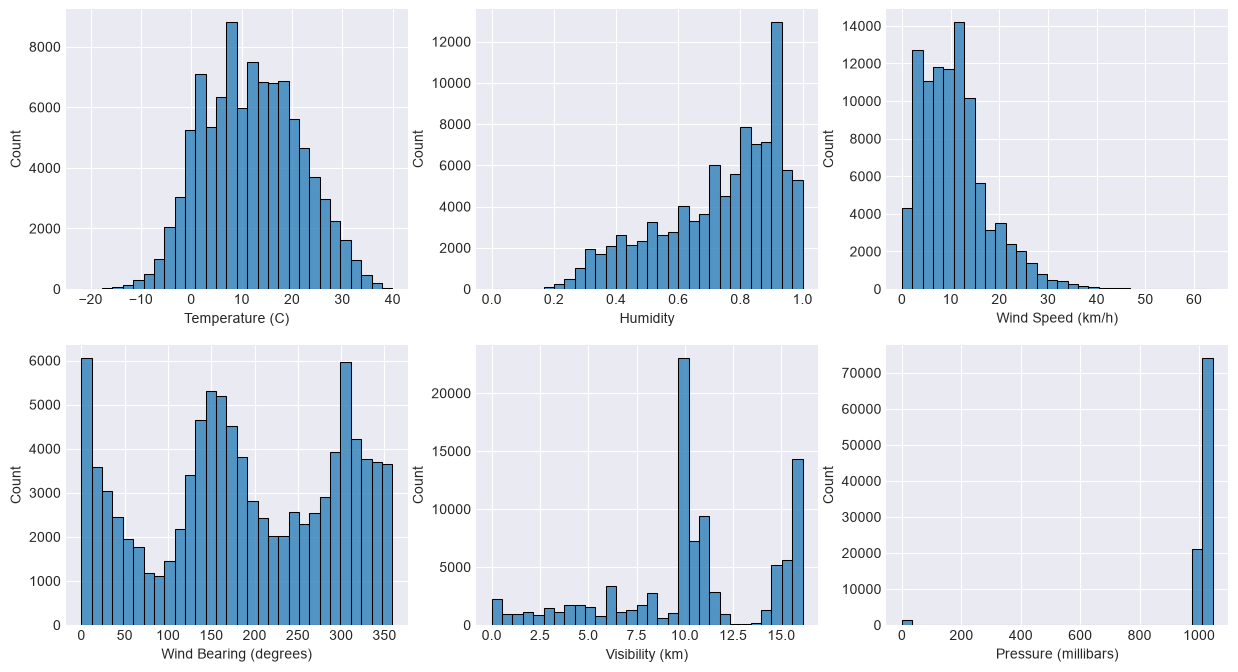

In [112]:
fig, axes = plt.subplots(2,3, figsize=(15,8))
axes= axes.ravel()
for count, col in enumerate(num_cols_df):
    ax=axes[count]
    sns.histplot(data = df, x = col, bins=30, ax=ax)

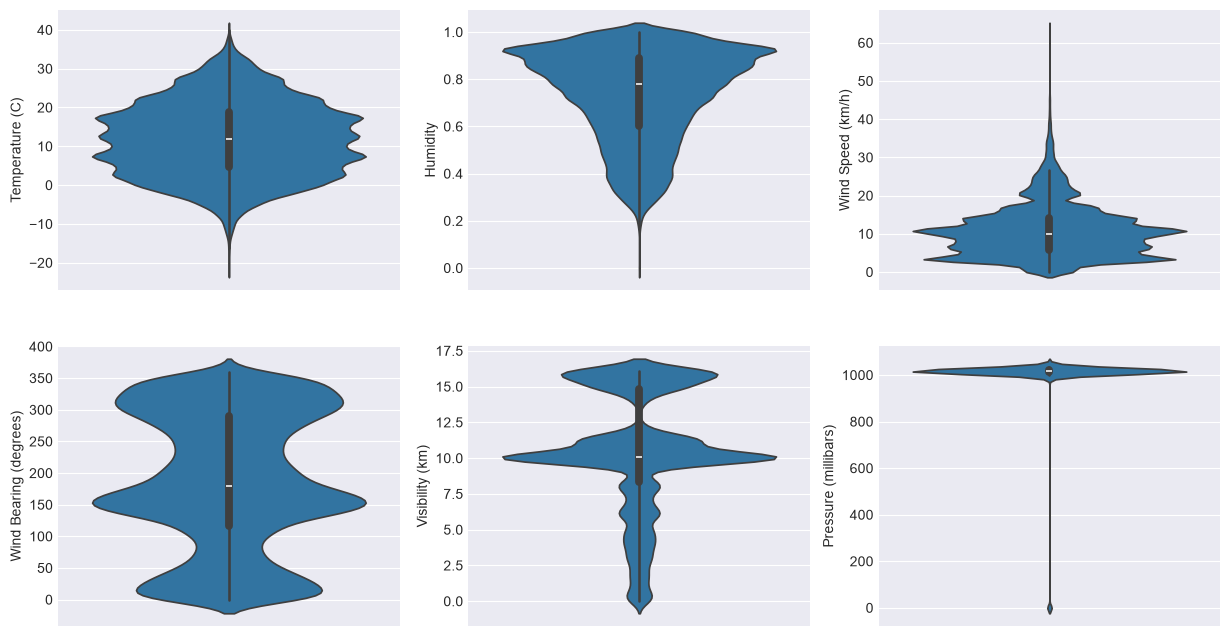

In [113]:
fig, axes = plt.subplots(2,3, figsize=(15,8))
axes= axes.ravel()
for count, col in enumerate(num_cols_df):
    ax=axes[count]
    sns.violinplot(data = df, y = col, ax=ax)

<Axes: >

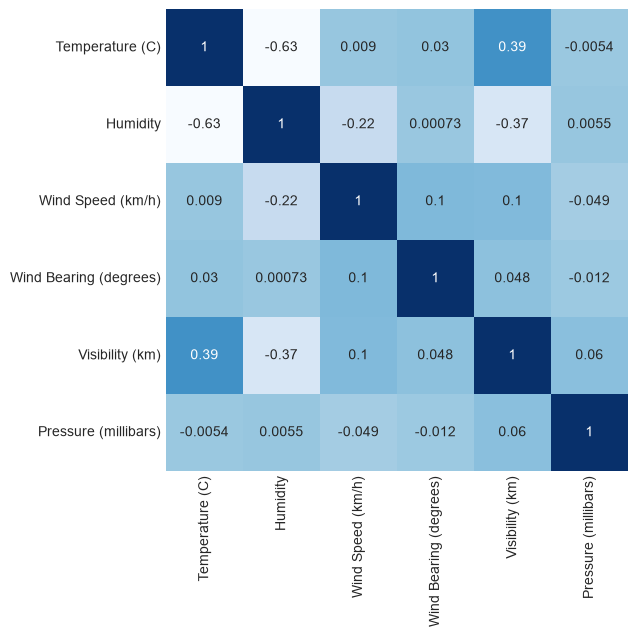

In [114]:
sns.heatmap(num_cols_df.corr(),cmap='Blues',annot=True, square=True,cbar=False)

In [115]:
temp_df=df[['datetime', 'Temperature (C)']]
temp_df= temp_df.sort_values('datetime',axis=0).reset_index(drop=True)
temp_df.rename({'Temperature (C)':'temp'},axis=1,inplace=True)
temp_df.head()

,datetime,temp
0,2005-12-31 23:00:00+00:00,0.577778
1,2006-01-01 00:00:00+00:00,1.161111
2,2006-01-01 01:00:00+00:00,1.666667
3,2006-01-01 02:00:00+00:00,1.711111
4,2006-01-01 03:00:00+00:00,1.183333


<Axes: xlabel='datetime'>

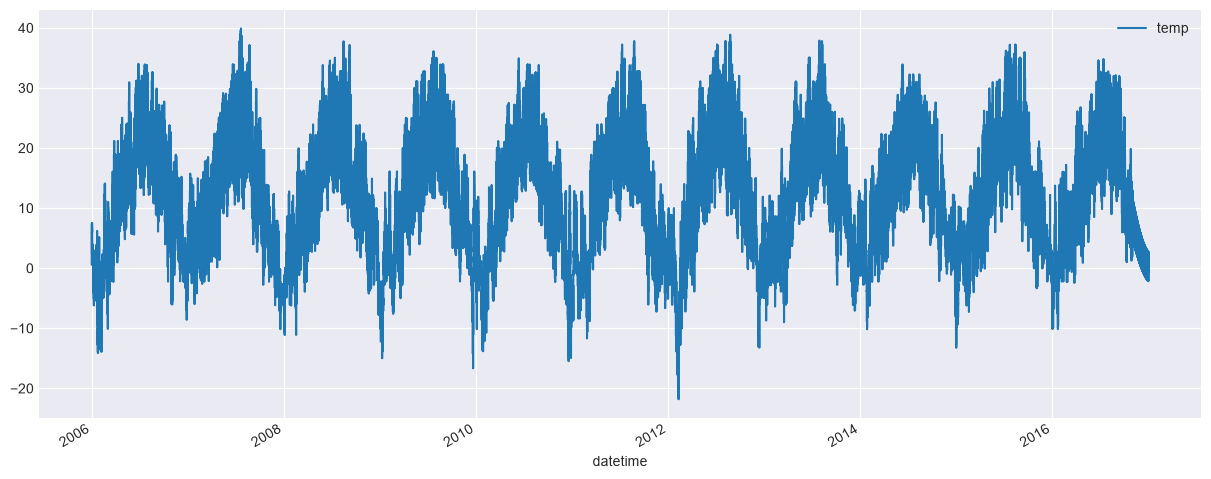

In [116]:
temp_df.plot(kind='line',x='datetime',y='temp')

In [117]:
h_units = 100
input_shape = (1, 10000)
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=input_shape))
model.add(tf.keras.layers.SimpleRNN(units=h_units, activation='tanh'))
model.add(tf.keras.layers.Dense(1))

In [118]:
Wax=model.get_weights()[0].shape
Waa=model.get_weights()[1].shape
baa=model.get_weights()[2].shape
Way=model.get_weights()[3].shape
bay=model.get_weights()[4].shape

print(f'Wax{Wax} ; Waa{Waa} ; baa{baa} ; Way{Way} : bay{bay}')

Wax(10000, 100) ; Waa(100, 100) ; baa(100,) ; Way(100, 1) : bay(1,)


In [119]:
time_step=24
y_idx=np.arange(time_step, temp_df.shape[0],time_step)


In [120]:
y_df=temp_df.iloc[y_idx]
y_df.head()

,datetime,temp
24,2006-01-01 23:00:00+00:00,5.422222
48,2006-01-02 23:00:00+00:00,1.694444
72,2006-01-03 23:00:00+00:00,2.200000
96,2006-01-04 23:00:00+00:00,1.666667
120,2006-01-05 23:00:00+00:00,1.805556


In [121]:
X_df= temp_df.iloc[range(len(y_df)*time_step)]
X_df.shape

(96432, 2)

In [122]:
X=np.reshape(X_df['temp'].to_numpy(), (y_df.shape[0], time_step))
X.shape, y_df.shape

((4018, 24), (4018, 2))

In [123]:
X=X[:,:23]
X.shape

(4018, 23)

In [124]:
X=X.reshape(X.shape[0], X.shape[1], 1)
X.shape

(4018, 23, 1)

In [125]:
split= int(y_df.shape[0]*(1-TEST_SIZE))

X_train = X[:split]
X_test=X[split:]
y_train=y_df['temp'].to_numpy()[:split]
y_test=y_df['temp'].to_numpy()[split:]
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(3214, 23, 1) (804, 23, 1) (3214,) (804,)


In [126]:
train_ds = tf.data.Dataset.from_tensor_slices((X_train,y_train))
train_ds = train_ds.cache()
train_ds = train_ds.shuffle(buffer_size=X_train.shape[0]).batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

In [127]:
test_ds = tf.data.Dataset.from_tensor_slices((X_test,y_test))
test_ds = test_ds.cache()
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

In [128]:
h_units = 256
input_shape = (time_step-1, 1)
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=input_shape))
model.add(tf.keras.layers.SimpleRNN(units=h_units, activation='tanh'))
model.add(tf.keras.layers.Dense(1))

In [129]:
model.compile(optimizer='adam',
            loss='mean_squared_error',
            metrics=[tf.keras.metrics.RootMeanSquaredError()]
)

In [130]:
history=model.fit(train_ds,
            validation_data=test_ds,
            epochs=EPOCHS
            )

Epoch 1/100


C:\Users\PGCP-AI\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 10.1188 - root_mean_squared_error: 3.1810 - val_loss: 0.9969 - val_root_mean_squared_error: 0.9984
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 1.5991 - root_mean_squared_error: 1.2646 - val_loss: 1.0068 - val_root_mean_squared_error: 1.0034
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 1.3699 - root_mean_squared_error: 1.1704 - val_loss: 0.7495 - val_root_mean_squared_error: 0.8658
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 1.1897 - root_mean_squared_error: 1.0907 - val_loss: 0.7746 - val_root_mean_squared_error: 0.8801
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 1.1148 - root_mean_squared_error: 1.0558 - val_loss: 0.7131 - val_root_mean_squared_error: 0.8445
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 1.1068 - root_mean_squared_error: 1.0521 - val_loss: 0.9220 - val_root_mean_squared_error: 0.9602
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/st

In [132]:
hist_df=pd.DataFrame(history.history)
hist_df.head()

,loss,root_mean_squared_error,val_loss,val_root_mean_squared_error
0,10.118831,3.181011,0.996858,0.998428
1,1.599093,1.264552,1.006819,1.003403
2,1.369901,1.170428,0.749530,0.865754
3,1.189718,1.090742,0.774559,0.880091
4,1.114779,1.055831,0.713131,0.844471


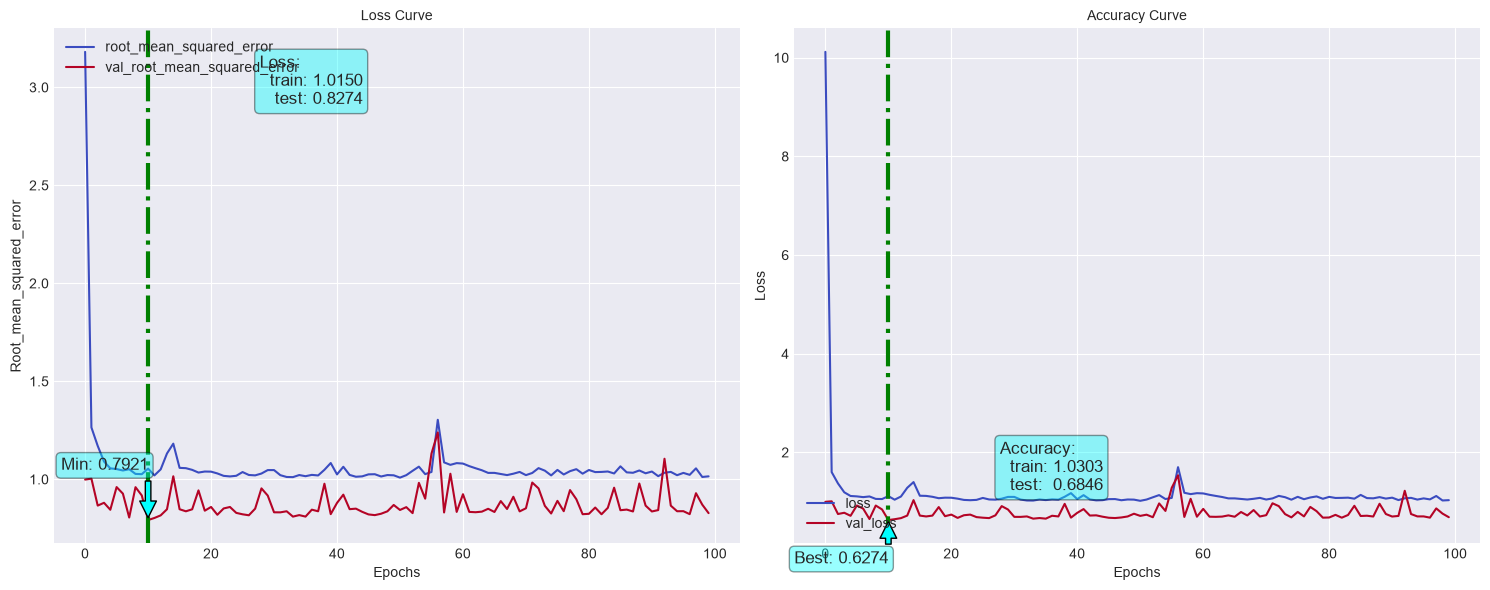

In [137]:
fn_plot_tf_hist(hist_df)

In [134]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
y_pred = np.append(y_train_pred,y_test_pred)

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


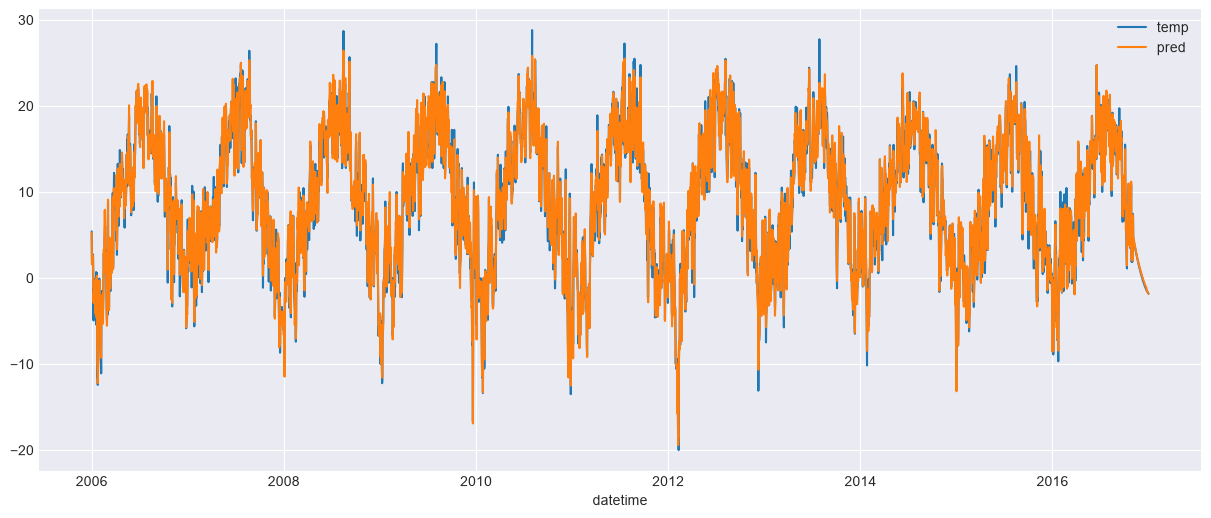

In [135]:
res_df=y_df.copy()
res_df['pred']=y_pred
res_df['datetime']=res_df['datetime'].dt.date
ax=res_df.plot(x='datetime',y=['temp','pred'])